In [1]:
from one.api import ONE
from brainbox.io.one import SessionLoader

from brainwidemap import bwm_query, load_good_units, load_trials_and_mask, bwm_units

In [2]:
one = ONE(base_url='https://openalyx.internationalbrainlab.org',password='international', mode='remote')
# Dataframe with info on all sessions and probes released for the BWM
bwm_df = bwm_query(one)
# Dataframe with information on all neurons used in the analyses in the BWM paper
unit_df = bwm_units(one)
unit_df.describe()

Connected to https://openalyx.internationalbrainlab.org as user "intbrainlab"
Loading bwm_query results from fixtures/2023_12_bwm_release.csv
Loading bwm_query results from fixtures/2023_12_bwm_release.csv
d16d0b38d392b18c0ce8b615ec89d60d7c901df2eeb3432986b62130af28ef01


,channels,depths,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,contamination,contamination_alt,drift,...,firing_rate,label,bitwise_fail,x,y,z,atlas_id,axial_um,lateral_um,spike_count_good
count,62990.000000,62990.000000,62990.000000,62990.000000,62990.000000,62990.000000,62990.000000,62990.000000,62990.000000,6.285300e+04,...,62990.000000,62990.0,62990.0,62990.000000,62990.000000,62990.000000,6.299000e+04,62990.000000,62990.000000,6.299000e+04
mean,180.509732,1820.041260,479.725242,0.000371,0.000099,0.000182,1.510372,0.325634,0.094669,5.638608e+05,...,11.281665,1.0,0.0,-0.001214,-0.002510,-0.003330,2.160946e+07,1820.031830,35.096619,5.409288e+04
std,106.153551,1061.609375,321.580315,0.001828,0.000453,0.000767,0.469793,5.683506,0.375921,1.236619e+06,...,16.913926,0.0,0.0,0.001584,0.002487,0.001361,9.827045e+07,1061.621978,19.161977,8.166459e+04
min,0.000000,20.000000,0.000000,0.000071,0.000015,0.000050,0.333361,0.000000,0.000000,3.160087e+02,...,0.050835,1.0,0.0,-0.004851,-0.007715,-0.007113,2.000000e+00,20.000000,0.000000,2.620000e+02
25%,88.000000,900.000000,217.000000,0.000200,0.000053,0.000098,1.210068,0.001544,0.002138,5.115363e+04,...,2.343102,1.0,0.0,-0.002154,-0.004133,-0.004206,2.330000e+02,900.000000,11.000000,1.112000e+04
50%,173.000000,1740.000000,432.000000,0.000279,0.000074,0.000137,1.440268,0.021411,0.020531,1.488845e+05,...,5.619522,1.0,0.0,-0.001398,-0.002476,-0.003356,6.720000e+02,1740.000000,43.000000,2.649550e+04
75%,273.000000,2740.000000,690.000000,0.000399,0.000108,0.000199,1.718291,0.070598,0.062897,4.755374e+05,...,12.570395,1.0,0.0,-0.000473,-0.001038,-0.002451,9.840000e+02,2740.000000,59.000000,6.060550e+04
max,383.000000,3840.000000,2145.000000,0.180919,0.048336,0.082691,6.690393,837.225816,22.640699,2.373887e+07,...,243.531726,1.0,0.0,0.003468,0.003596,0.000039,6.144543e+08,3840.000000,59.000000,1.503079e+06


In [3]:
unit_df.columns

Index(['Beryl', 'eid', 'channels', 'depths', 'uuids', 'cluster_id', 'amp_max',
       'amp_min', 'amp_median', 'amp_std_dB', 'contamination',
       'contamination_alt', 'drift', 'missed_spikes_est', 'noise_cutoff',
       'presence_ratio', 'presence_ratio_std', 'slidingRP_viol', 'spike_count',
       'slidingRP_viol_forced', 'max_confidence', 'min_contamination',
       'n_spikes_below2', 'firing_rate', 'label', 'bitwise_fail', 'ks2_label',
       'x', 'y', 'z', 'acronym', 'atlas_id', 'axial_um', 'lateral_um', 'pid',
       'spike_count_good'],
      dtype='object')

In [7]:
print(clusters.keys())

dict_keys(['amps', 'depths', 'brainLocationAcronyms_ccf_2017', 'channels', 'peakToTrough', 'brainLocationIds_ccf_2017', 'waveforms', 'mlapdv', 'uuids', 'waveformsChannels', 'metrics'])


In [3]:
unit_df

,Beryl,eid,channels,depths,uuids,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,...,ks2_label,x,y,z,acronym,atlas_id,axial_um,lateral_um,pid,spike_count_good
0,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,61,620.0,c5cabbda-1f74-4168-ad5e-7c5a2f533d9f,79,0.000300,0.000081,0.000158,1.056608,...,good,-0.002378,-0.000250,-0.006350,CNU,23,620.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,167762.0
1,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,68,700.0,5b5176f2-228f-46b5-85c8-205cf9d90a53,88,0.000323,0.000123,0.000221,0.972567,...,good,-0.002364,-0.000250,-0.006272,CNU,23,700.0,43.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,16139.0
2,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,71,720.0,19930b44-2f8a-44e1-a8ce-46184f7334cb,91,0.000187,0.000057,0.000109,1.266665,...,good,-0.002364,-0.000250,-0.006252,CNU,23,720.0,27.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,34700.0
3,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,77,780.0,304c2251-f207-4926-ba28-967ebbda4473,105,0.000208,0.000046,0.000079,1.655816,...,good,-0.002364,-0.000250,-0.006192,CNU,23,780.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,224475.0
4,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,82,840.0,4bd714b8-5753-4561-87e5-2ef3126426b7,115,0.000346,0.000085,0.000163,1.334542,...,good,-0.002364,-0.000250,-0.006132,CNU,23,840.0,59.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,292062.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62985,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,55,560.0,3beabe91-423a-49c3-8e55-fb846457c89d,152,0.000258,0.000093,0.000139,1.890024,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,27.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,2307.0
62986,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,57,580.0,78952ffb-d419-464e-96e9-2b22723aa58b,158,0.000910,0.000085,0.000170,3.049439,...,good,-0.001725,-0.006281,-0.004621,HB,765,580.0,11.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,544566.0
62987,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,54,560.0,2490ff61-baae-4e8e-a90e-d34e851b8cd1,160,0.000213,0.000069,0.000119,1.654493,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37240.0
62988,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,58,600.0,945e9b3b-0a09-4272-b56e-7640e1e1f647,161,0.000247,0.000070,0.000109,1.398105,...,good,-0.001735,-0.006276,-0.004598,HB,765,600.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37519.0


In [39]:
unit_df['spike_count_good'].max()

1503079.0

In [45]:
unit_df['cluster_id'].min()

0

In [41]:
unit_df[unit_df['pid']=='56f2a378-78d2-4132-b3c8-8c1ba82be598']

,Beryl,eid,channels,depths,uuids,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,...,ks2_label,x,y,z,acronym,atlas_id,axial_um,lateral_um,pid,spike_count_good
23551,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,30,-0.003303,37c3d271-4a22-40ab-b95f-d663f286f57e,114,0.000379,0.000055,0.000187,3.952382,...,good,-0.002338,-0.002525,-0.003303,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,13977.0
23552,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,30,-0.003303,9d145223-eda7-457d-adf1-5d34f4deb589,117,0.000559,0.000156,0.000303,1.226605,...,good,-0.002338,-0.002525,-0.003303,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,15299.0
23553,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,31,-0.003303,1a9e6f72-b50f-4382-b487-d0b71c211590,119,0.000610,0.000190,0.000307,1.007452,...,good,-0.002338,-0.002525,-0.003303,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,14938.0
23554,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,32,-0.003283,d879cfe4-27b7-4f48-b966-12ae4b67d5d7,122,0.000176,0.000057,0.000110,1.051495,...,good,-0.002338,-0.002525,-0.003283,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,34779.0
23555,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,33,-0.003283,68ff1ec5-959a-4f05-a3e1-7c75edf3c955,123,0.000312,0.000061,0.000125,1.148455,...,good,-0.002338,-0.002525,-0.003283,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,53340.0
23556,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,34,-0.003263,64b2540e-265f-46d8-9799-5ac815cb1706,127,0.000340,0.000098,0.000185,1.184218,...,good,-0.002338,-0.002525,-0.003263,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,26037.0
23557,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,32,-0.003283,0a533fdf-1749-4b74-92fd-d23dbcd2420d,131,0.000709,0.000251,0.000437,0.769811,...,good,-0.002338,-0.002525,-0.003283,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,24550.0
23558,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,36,-0.003243,96686fe6-08c0-4f50-9972-261c3be51f43,134,0.000519,0.000169,0.000303,1.091702,...,mua,-0.002338,-0.002525,-0.003243,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,9400.0
23559,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,36,-0.003243,ca0f3198-0206-4af6-9460-073f3209f36a,135,0.000556,0.000200,0.000384,0.850754,...,good,-0.002338,-0.002525,-0.003243,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,8808.0
23560,LGd,6713a4a7-faed-4df2-acab-ee4e63326f8d,37,-0.003243,21ae2c22-16d7-4519-8dbc-bb4b7029d177,140,0.000220,0.000064,0.000133,1.720424,...,good,-0.002338,-0.002525,-0.003243,TH,496345668,-0.002338,-0.002525,56f2a378-78d2-4132-b3c8-8c1ba82be598,10603.0


In [25]:
import plotly.express as px

# 假设 unit_df 是你的数据框，包含 'axial_um', 'lateral_um', 'depths' 以及 'x', 'y', 'z' 列
# 这里不生成随机数据，假设你有一个已经存在的 unit_df 数据框

# 计算新的坐标，减去同行的 'x', 'y', 'z' 列
unit_df['axial_um'] = unit_df['x'] 
unit_df['lateral_um'] = unit_df['y'] 
unit_df['depths'] = unit_df['z']

# 使用 Plotly 绘制 3D 散点图
fig = px.scatter_3d(unit_df, x='axial_um', y='lateral_um', z='depths',
                    labels={'axial_um': 'Axial (um)', 'lateral_um': 'Lateral (um)', 'depths': 'Depths (um)'},
                    title="3D Scatter Plot of Adjusted Axial, Lateral, and Depths")

fig.update_traces(marker=dict(size=1))

# 显示图形
fig.show()


Data shape: (528, 320, 456)
Spacing (directions): [[25.  0.  0.]
 [ 0. 25.  0.]
 [ 0.  0. 25.]]
Origin: [0. 0. 0.]


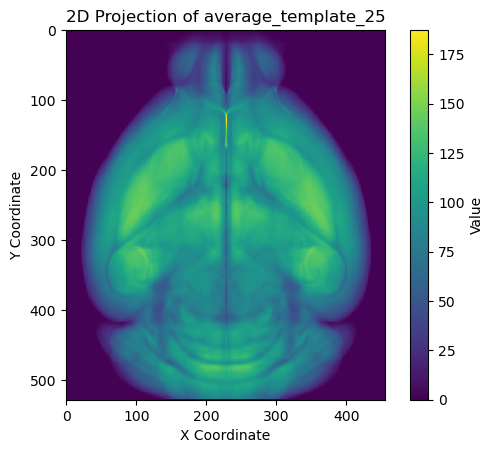

In [34]:
import nrrd
import numpy as np
import matplotlib.pyplot as plt

# Load the NRRD file
data, header = nrrd.read('/home/ylx/project/SC_FC/BWM/histology/ATLAS/Needles/Allen/average_template_25.nrrd')

# Get the shape of the data
shape = data.shape

# Get the coordinate range (using the header for spacing and origin info)
spacing = header.get('space directions', None)
origin = header.get('space origin', None)

# Print the shape, spacing, and origin for reference
print("Data shape:", shape)
print("Spacing (directions):", spacing)
print("Origin:", origin)

# Perform a 2D projection by averaging along the Z axis (axis=2)
projection = np.mean(data, axis=1)  # You can change axis if needed (e.g., axis=1 or axis=0)

# Plot the 2D projection
plt.imshow(projection, cmap='viridis', interpolation='none')
plt.colorbar(label='Value')
plt.title('2D Projection of average_template_25')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.show()


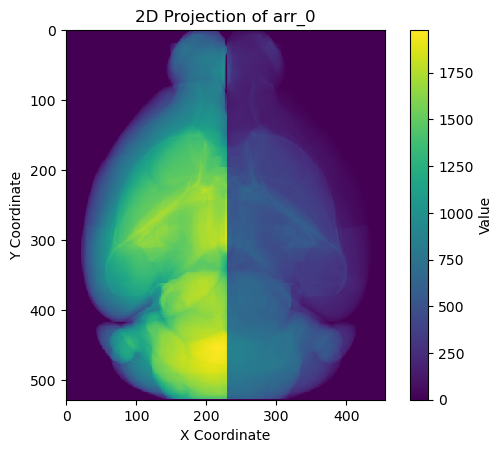

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# 加载 NPZ 文件
file_path = '/home/ylx/project/SC_FC/BWM/histology/ATLAS/Needles/Allen/annotation_25_lut_v01.npz'
data = np.load(file_path)

# 假设我们要查看第一个数组
array_key = data.files[0]  # 选择第一个数组作为示例
array = data[array_key]

# 对数据进行某种形式的投影（例如：取 Z 轴的平均值）
projection = np.mean(array, axis=2)  # 沿 z 轴方向取平均

# 绘制二维投影
plt.imshow(projection, cmap='viridis', interpolation='none')
plt.colorbar(label='Value')
plt.title(f'2D Projection of {array_key}')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.show()


In [18]:
min_x = unit_df['x'].min()
max_x = unit_df['x'].max()

min_y = unit_df['y'].min()
max_y = unit_df['y'].max()

min_z = unit_df['z'].min()
max_z = unit_df['z'].max()

print(f"X axis range: {min_x} to {max_x}")
print(f"Y axis range: {min_y} to {max_y}")
print(f"Z axis range: {min_z} to {max_z}")


X axis range: -0.004851 to 0.003468
Y axis range: -0.007715 to 0.003596
Z axis range: -0.007113 to 3.9e-05


In [4]:
pid = bwm_df.pid[1]
pid

'47be9ae4-290f-46ab-b047-952bc3a1a509'

In [11]:
spikes, clusters = load_good_units(one, pid, compute_metrics=True)

In [13]:
clusters

,channels,depths,uuids,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,contamination,contamination_alt,...,bitwise_fail,x,y,z,acronym,atlas_id,axial_um,lateral_um,labels,rawInd
0,1,20.0,862dbd05-ce8f-45f0-912e-def67727b577,7,0.000232,0.000057,0.000090,1.954966,1.050934,0.609162,...,0,-0.003084,-0.001909,-0.007113,COApl,655,20.0,11.0,0,1
1,50,520.0,1d14c6c6-dd82-4b39-9f00-5b6124eede2e,36,0.000124,0.000027,0.000052,1.833819,0.103038,0.088342,...,0,-0.003013,-0.001806,-0.006643,COApl,655,520.0,59.0,0,50
2,57,580.0,f0ca446e-08eb-475a-ab43-b14dbb5b34c1,59,0.000327,0.000096,0.000165,1.228854,0.122780,0.103813,...,0,-0.003013,-0.001800,-0.006584,COApl,655,580.0,11.0,0,57
3,57,580.0,1cfab56b-dc74-497a-b6e2-b221a2099eab,67,0.000340,0.000115,0.000196,1.226725,0.000000,0.000000,...,0,-0.003013,-0.001800,-0.006584,COApl,655,580.0,11.0,0,57
4,62,640.0,302d3fe3-3d76-4850-a044-9368643b9888,74,0.000371,0.000069,0.000137,1.403536,0.019932,0.018390,...,0,-0.003013,-0.001800,-0.006524,COApl,655,640.0,59.0,0,62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164,294,2960.0,b22bdccb-0ef5-4f15-a117-add019724405,1046,0.000409,0.000087,0.000245,1.739503,0.000000,0.000000,...,0,-0.002788,-0.001437,-0.004291,int,6,2960.0,59.0,0,294
165,301,3020.0,6b99eb46-4b59-4d5a-9c11-d3f7524074ed,1051,0.000585,0.000082,0.000338,2.109564,0.065944,0.058466,...,0,-0.002788,-0.001422,-0.004233,int,6,3020.0,11.0,0,301
166,313,3140.0,b21e5926-ae61-40e0-bbae-1179e10d674c,1056,0.000359,0.000124,0.000254,1.100698,0.000000,0.000000,...,0,-0.002781,-0.001400,-0.004117,int,6,3140.0,11.0,0,313
167,85,860.0,28e060c1-54df-4d6a-b4ad-c63400422804,1071,0.000269,0.000090,0.000156,0.974014,0.257697,0.199792,...,0,-0.002985,-0.001797,-0.006307,CTXsp,703,860.0,11.0,0,85


In [3]:
all_units = []
for pid in bwm_df.pid:
    try:
        # 加载该 probe 的 spike & cluster 数据
        spikes, clusters = load_good_units(one, pid, compute_metrics=False)

        # 遍历每个 cluster
        for _, row in clusters.iterrows():
            cluster_id = row["cluster_id"]

            # 提取该 neuron 的 spike 时间
            spike_times = spikes["times"][spikes["clusters"] == cluster_id]

            # 保存成 dict，便于之后做 DataFrame
            unit_dict = {
                "pid": pid,
                "cluster_id": cluster_id,
                "x": row["x"],
                "y": row["y"],
                "z": row["z"],
                "acronym": row["acronym"],
                "atlas_id": row["atlas_id"],
                "spike_times": spike_times  # 注意这里存的是数组
            }
            all_units.append(unit_dict)

    except Exception as e:
        print(f"跳过 {pid}, 出错: {e}")
        continue

100%|███████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.40it/s]
100%|███████████████████████████████████████████| 4/4.0 [00:02<00:00,  1.63it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.32it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:01<00:00,  1.76it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.26it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:01<00:00,  1.55it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.42it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.38it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:01<00:00,  1.84it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:01<00:00,  1.64it/s]
100%|███████████████████████████████████████████| 3/3.0 [00:01<00:00,  1.60it/s]
100%|███████████████████████████████████████████| 4/4.0 [00:02<00:00,  1.50it/s]
100%|███████████████████████

In [ ]:
units_df_all = pd.DataFrame(all_units)